# Biodiversity in National Parks

## Introduction
This project analysis National Park Service data on the species recorded in four US national parks,
to find out whether some types of species are more likely to become endangered than others.

**Questions**
1. What is the distribution of conservation statuses across species?
2. Are certain types of species more likely to be protected?
3. Are the differences between species types statistically significant?
4. Which species are observed most in each park?

**Data**
- `species_info.csv`: each species' category, scientific name, common names and conservation status
- `observations.csv`: sightings of each species in each park over the past 7 days

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

species = pd.read_csv("species_info.csv")
observations = pd.read_csv("observations.csv")

species.head()
observations.head()

,scientific_name,park_name,observations
0,Vicia benghalensis,Great Smoky Mountains National Park,68
1,Neovison vison,Great Smoky Mountains National Park,77
2,Prunus subcordata,Yosemite National Park,138
3,Abutilon theophrasti,Bryce National Park,84
4,Githopsis specularioides,Great Smoky Mountains National Park,85


## Inspecting the Data ----

In [2]:
print(species.shape)

(5824, 4)


In [3]:
print(observations.shape)

(23296, 3)


In [4]:
species.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5824 entries, 0 to 5823
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   category             5824 non-null   object
 1   scientific_name      5824 non-null   object
 2   common_names         5824 non-null   object
 3   conservation_status  191 non-null    object
dtypes: object(4)
memory usage: 182.1+ KB


In [5]:
observations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23296 entries, 0 to 23295
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   scientific_name  23296 non-null  object
 1   park_name        23296 non-null  object
 2   observations     23296 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 546.1+ KB


In [6]:
species.nunique()

category                  7
scientific_name        5541
common_names           5504
conservation_status       4
dtype: int64

In [7]:
observations.nunique()

scientific_name    5541
park_name             4
observations        304
dtype: int64

In [8]:
species.category.value_counts()

Vascular Plant       4470
Bird                  521
Nonvascular Plant     333
Mammal                214
Fish                  127
Amphibian              80
Reptile                79
Name: category, dtype: int64

In [9]:
observations.park_name.value_counts()

Great Smoky Mountains National Park    5824
Yosemite National Park                 5824
Bryce National Park                    5824
Yellowstone National Park              5824
Name: park_name, dtype: int64

In [10]:
species.conservation_status.value_counts(dropna = False)

NaN                   5633
Species of Concern     161
Endangered              16
Threatened              10
In Recovery              4
Name: conservation_status, dtype: int64

In [11]:
print(observations.park_name.value_counts())
observations.observations.describe()

Great Smoky Mountains National Park    5824
Yosemite National Park                 5824
Bryce National Park                    5824
Yellowstone National Park              5824
Name: park_name, dtype: int64


count    23296.000000
mean       142.287904
std         69.890532
min          9.000000
25%         86.000000
50%        124.000000
75%        195.000000
max        321.000000
Name: observations, dtype: float64

## Data Cleaning Time >>>

In [12]:
species["conservation_status"] = species["conservation_status"].fillna("Not under protection")
species.conservation_status.value_counts()

Not under protection    5633
Species of Concern       161
Endangered                16
Threatened                10
In Recovery                4
Name: conservation_status, dtype: int64

In [13]:
species[species.duplicated("scientific_name", keep=False)].sort_values("scientific_name").head(10)

,category,scientific_name,common_names,conservation_status
5553,Vascular Plant,Agrostis capillaris,"Colonial Bent, Colonial Bentgrass",Not under protection
2132,Vascular Plant,Agrostis capillaris,Rhode Island Bent,Not under protection
2134,Vascular Plant,Agrostis gigantea,Redtop,Not under protection
5554,Vascular Plant,Agrostis gigantea,"Black Bent, Redtop, Water Bentgrass",Not under protection
4178,Vascular Plant,Agrostis mertensii,"Arctic Bentgrass, Northern Bentgrass",Not under protection
2136,Vascular Plant,Agrostis mertensii,Northern Agrostis,Not under protection
2138,Vascular Plant,Agrostis scabra,"Rough Bentgrass, Rough Hairgrass",Not under protection
5556,Vascular Plant,Agrostis scabra,"Rough Bent, Rough Bentgrass, Ticklegrass",Not under protection
4182,Vascular Plant,Agrostis stolonifera,"Carpet Bentgrass, Creeping Bent, Creeping Bent...",Not under protection
2139,Vascular Plant,Agrostis stolonifera,Creeping Bentgrass,Not under protection


In [14]:
status_count = species.groupby("scientific_name").conservation_status.nunique()
conflicts = status_count[status_count > 1].index
species[species.scientific_name.isin(conflicts)]

,category,scientific_name,common_names,conservation_status
8,Mammal,Canis lupus,Gray Wolf,Endangered
560,Fish,Oncorhynchus mykiss,Rainbow Trout,Not under protection
3020,Mammal,Canis lupus,"Gray Wolf, Wolf",In Recovery
3283,Fish,Oncorhynchus mykiss,Rainbow Trout,Threatened
4448,Mammal,Canis lupus,"Gray Wolf, Wolf",Endangered


In [15]:
severity = {"Endangered": 0, "Threatened": 1, "Species of Concern": 2,
            "In Recovery": 3, "Not under protection": 4}

species["severity"] = species["conservation_status"].map(severity)
species = (species.sort_values("severity")
                  .drop_duplicates("scientific_name")
                  .drop(columns="severity")
                  .reset_index(drop=True))
species.shape

(5541, 4)

In [16]:
observations = (observations.groupby(["scientific_name", "park_name"], as_index=False).observations.sum())
observations.shape




(22164, 3)

## Cleaning decisions
- Blank conservation statuses became "Not under protection", since a blank means no protection is needed.
- Species listed more than once keep only their most serious status, so no protected status is lost.
- Sightings were summed per species per park, because each listing of a species had its own observation rows.


## Analysis


In [17]:
protected = species[species.conservation_status != "Not under protection"]
status_by_category = (protected.groupby(["conservation_status", "category"])
                               .scientific_name.count()
                               .unstack(fill_value=0))
status_by_category

category,Amphibian,Bird,Fish,Mammal,Nonvascular Plant,Reptile,Vascular Plant
conservation_status,,,,,,,
Endangered,1,4,3,6,0,0,1
In Recovery,0,3,0,0,0,0,0
Species of Concern,4,68,4,22,5,5,43
Threatened,2,0,4,2,0,0,2


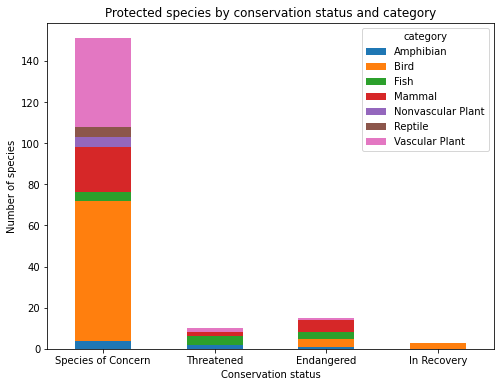

In [19]:
order = ["Species of Concern", "Threatened", "Endangered", "In Recovery"]
ax = status_by_category.loc[order].plot(kind="bar", stacked=True, figsize=(8, 6))
ax.set_xlabel("Conservation status")
ax.set_ylabel("Number of species")
ax.set_title("Protected species by conservation status and category")
plt.xticks(rotation=0)
plt.show()


In [22]:
species["is_protected"] = species.conservation_status != "Not under protection"

counts = pd.crosstab(species.category, species.is_protected)
counts.columns = ["not_protected", "protected"]
counts["percent_protected"] = (counts.protected / (counts.protected + counts.not_protected) * 100).round(1)
counts.sort_values("percent_protected", ascending=False)

,not_protected,protected,percent_protected
category,,,
Mammal,146,30,17.0
Bird,413,75,15.4
Amphibian,72,7,8.9
Fish,114,11,8.8
Reptile,73,5,6.4
Nonvascular Plant,328,5,1.5
Vascular Plant,4216,46,1.1


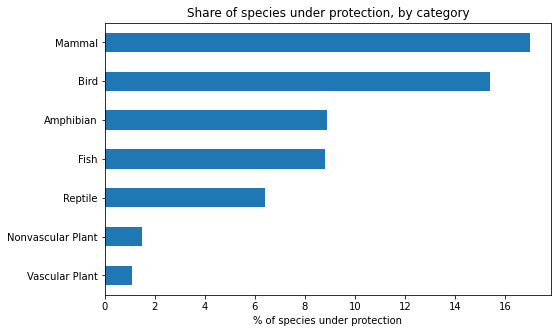

In [23]:
counts.sort_values("percent_protected").percent_protected.plot(kind="barh", figsize=(8, 5))
plt.xlabel("% of species under protection")
plt.ylabel("")
plt.title("Share of species under protection, by category")
plt.show()

In [24]:
def compare(category_a, category_b):
    table = counts.loc[[category_a, category_b], ["protected", "not_protected"]]
    chi2, p, dof, expected = chi2_contingency(table)
    return round(p, 4)

compare("Mammal", "Bird")

NameError: name 'chi2_contingency' is not defined